# Activity 1: Predictive Analytics — Smart PH Crop Recommendation System
**STIWNU Computing Seminar • November 23, 2026**  
**Recommended Colab Runtime:** Default **CPU** (saves your free GPU quota for Activity 2!)

### Learning Objectives
1. Gather an open agricultural dataset cleanly using `kagglehub` (with an automatic offline fallback).
2. Inspect data quality (missing values, duplicates, class balance, and feature correlations).
3. Prevent **Data Leakage** by performing a **Stratified Split** BEFORE scaling and using `scikit-learn` **Pipelines**.
4. Compare **Logistic Regression** vs. **Random Forest** using **5-Fold Cross-Validation** and **Macro F1-Score**.
5. Interpret the model via **Feature Importance**, export as `.joblib`, and run a **Live Gradio Web Application**.

In [1]:
# ==============================================================================
# CELL 1: Install & Import Required Libraries
# Note: '-q' runs pip in quiet mode to keep Colab output clean.
# ==============================================================================
!pip install -q kagglehub gradio joblib

import os
import glob
import joblib
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

sns.set_theme(style='whitegrid')
print('All libraries imported successfully!')

All libraries imported successfully!


## Step 1: Dataset Gathering
We pull the public **Crop Recommendation Dataset** (2,200 soil & climate rows across 22 crops including rice, maize, banana, coconut, coffee, and mango). If campus Wi-Fi blocks Kaggle, the fallback block automatically builds a realistic Philippine crop dataset so your lab never stalls.

In [2]:
# ==============================================================================
# CELL 2: Gather Public Dataset via KaggleHub (With Automatic Safety Fallback)
# ==============================================================================
try:
    dataset_dir = kagglehub.dataset_download('atharvaingle/crop-recommendation-dataset')
    csv_files = glob.glob(os.path.join(dataset_dir, '*.csv'))
    df = pd.read_csv(csv_files[0])
    print(f'Loaded live Kaggle dataset: {csv_files[0]}')
except Exception as e:
    print(f'Network fallback triggered ({e}). Generating synthetic PH crop dataset...')
    np.random.seed(42)
    profiles = {
        'rice':    (80, 48, 40, 24, 82, 6.4, 230),
        'maize':   (78, 48, 20, 22, 65, 6.2, 85),
        'banana':  (100, 82, 50, 27, 80, 6.0, 105),
        'coconut': (22, 17, 30, 27, 95, 6.0, 175),
        'coffee':  (101, 29, 30, 25, 59, 6.8, 158),
        'mango':   (20, 27, 30, 31, 50, 5.8, 95),
    }
    rows = []
    for crop, (n, p, k, t, h, ph, r) in profiles.items():
        for _ in range(150):
            rows.append([
                max(0, n + np.random.normal(0, 10)),
                max(0, p + np.random.normal(0, 6)),
                max(0, k + np.random.normal(0, 5)),
                t + np.random.normal(0, 2),
                np.clip(h + np.random.normal(0, 5), 10, 100),
                np.clip(ph + np.random.normal(0, 0.4), 3.5, 9.0),
                max(10, r + np.random.normal(0, 25)),
                crop
            ])
    df = pd.DataFrame(rows, columns=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'])

print(f'Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns')
df.head()

Using Colab cache for faster access to the 'crop-recommendation-dataset' dataset.
Loaded live Kaggle dataset: /kaggle/input/crop-recommendation-dataset/Crop_recommendation.csv
Dataset Shape: 2200 rows x 8 columns


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## Step 2: Exploratory Data Analysis (EDA)
Always inspect your raw data BEFORE writing any training code! Check for missing cells, duplicates, class imbalance, and sensor correlations.

--- 1. Missing Values per Column ---
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

--- 2. Duplicate Rows ---
Duplicate count: 0

--- 3. Class Balance (First 10 Crops) ---
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
Name: count, dtype: int64

--- 4. Summary Statistics (Check for Impossible Outliers!) ---


,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


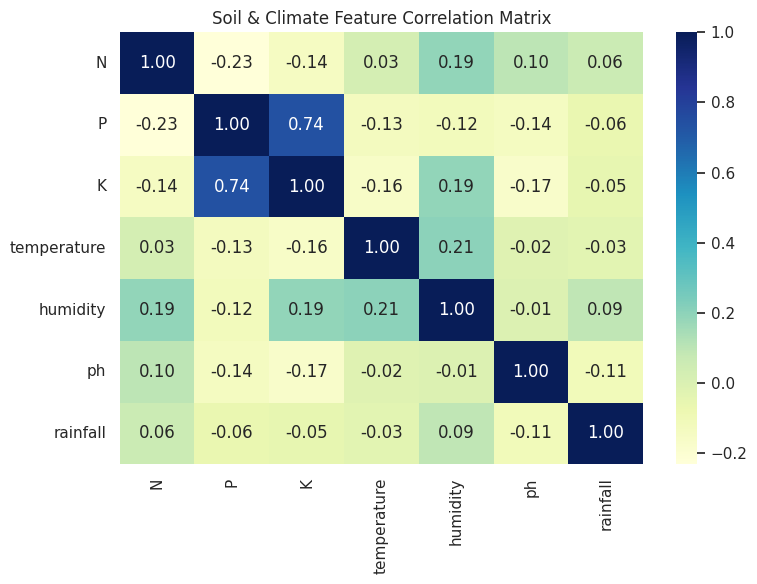

In [3]:
# ==============================================================================
# CELL 3: Inspect Data Quality & Feature Correlations
# ==============================================================================
numeric_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

print('--- 1. Missing Values per Column ---')
print(df.isnull().sum())

print('\n--- 2. Duplicate Rows ---')
print('Duplicate count:', df.duplicated().sum())

print('\n--- 3. Class Balance (First 10 Crops) ---')
print(df['label'].value_counts().head(10))

print('\n--- 4. Summary Statistics (Check for Impossible Outliers!) ---')
display(df[numeric_cols].describe().round(2))

# Correlation Heatmap (Great visual for Thesis Chapter 4!)
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Soil & Climate Feature Correlation Matrix')
plt.tight_layout()
plt.show()

## Step 3: Clean & Split FIRST (Preventing Data Leakage)
**Golden Rule:** Always lock away your unseen Test Set (`20%`) BEFORE fitting any `StandardScaler`. Using `stratify=y` guarantees every crop appears in exact equal proportions in both splits.

In [4]:
# ==============================================================================
# CELL 4: Drop Duplicates, Separate Features (X) & Target (y), and SPLIT FIRST
# ==============================================================================
df = df.drop_duplicates().reset_index(drop=True)

X = df[numeric_cols]   # Input Features
y = df['label']        # Target Label (Crop Name)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,    # 20% locked away as the Final Board Exam
    random_state=42,   # Ensures reproducible thesis results
    stratify=y         # Keeps identical crop ratios in train & test
)

print(f'Training rows: {X_train.shape[0]} | Unseen Test rows: {X_test.shape[0]}')

Training rows: 1760 | Unseen Test rows: 440


## Step 4: Leakage-Free Pipelines & Model Comparison (5-Fold CV)
By placing `StandardScaler()` inside a `Pipeline`, cross-validation automatically fits scaling statistics ONLY on the training folds—zero data leakage!

In [5]:
# ==============================================================================
# CELL 5: Compare Logistic Regression vs. Random Forest via 5-Fold CV
# ==============================================================================
# Baseline Model: Linear Logistic Regression
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

# Contender Model: Non-Linear Random Forest Ensemble
pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=150, random_state=42))
])

# Evaluate both cleanly on TRAINING data using 5-Fold Cross-Validation
for name, pipe in [('Logistic Regression', pipe_lr), ('Random Forest', pipe_rf)]:
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1_macro')
    print(f'{name:22s} | 5-Fold CV Macro F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})')

# Train our winning Random Forest pipeline on the full training split
best_model = pipe_rf
best_model.fit(X_train, y_train)
print('\nWinning pipeline (Random Forest) trained successfully!')

Logistic Regression    | 5-Fold CV Macro F1: 0.9674 (+/- 0.0115)
Random Forest          | 5-Fold CV Macro F1: 0.9943 (+/- 0.0054)

Winning pipeline (Random Forest) trained successfully!


## Step 5: Honest Evaluation on Unseen Test Set & Feature Importance
Now we unlock `X_test` **once** to report our true thesis metrics (Accuracy, Precision, Recall, Macro F1) and inspect which soil/climate features drove the AI's decisions.

FINAL UNSEEN TEST ACCURACY : 0.9955
FINAL UNSEEN TEST MACRO F1 : 0.9955

--- Full Classification Report ---
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00    

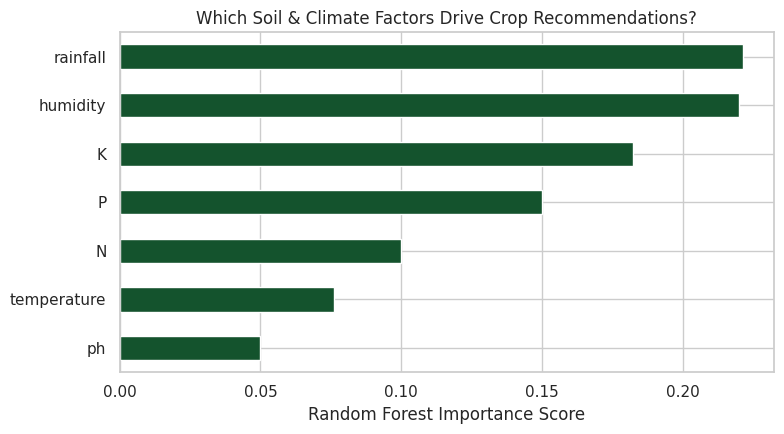

In [6]:
# ==============================================================================
# CELL 6: Final Unseen Test Evaluation & Feature Importance Chart
# ==============================================================================
y_pred = best_model.predict(X_test)

print(f'FINAL UNSEEN TEST ACCURACY : {accuracy_score(y_test, y_pred):.4f}')
print(f'FINAL UNSEEN TEST MACRO F1 : {f1_score(y_test, y_pred, average="macro"):.4f}\n')
print('--- Full Classification Report ---')
print(classification_report(y_test, y_pred))

# Plot Feature Importance (Answers: 'Which sensor matters most?')
importances = best_model.named_steps['model'].feature_importances_
feat_imp = pd.Series(importances, index=numeric_cols).sort_values(ascending=True)

plt.figure(figsize=(8, 4.5))
feat_imp.plot(kind='barh', color='#14532D')
plt.title('Which Soil & Climate Factors Drive Crop Recommendations?')
plt.xlabel('Random Forest Importance Score')
plt.tight_layout()
plt.show()

## Step 6: Export Pipeline (`.joblib`) & Launch Sample Application (Gradio)
Saving the entire `Pipeline` bundles **both** `StandardScaler` and `RandomForestClassifier` into one single `.joblib` file—ready for FastAPI, Flask, or Streamlit!

In [7]:
# ==============================================================================
# CELL 7: Export & Verify Reload of Trained Pipeline
# ==============================================================================
MODEL_PATH = 'ph_crop_recommender_pipeline.joblib'
joblib.dump(best_model, MODEL_PATH)
print(f'Exported pipeline to {MODEL_PATH} ({os.path.getsize(MODEL_PATH)/1024:.1f} KB)')

# Reload from disk just like a real production web backend would
loaded_pipeline = joblib.load(MODEL_PATH)
print('Reload verification passed!')

Exported pipeline to ph_crop_recommender_pipeline.joblib (5258.3 KB)
Reload verification passed!


In [8]:
# ==============================================================================
# CELL 8: Sample Run Application — Interactive Gradio Web App
# Tip: If campus firewall blocks public share links, change share=True to share=False.
# ==============================================================================
import gradio as gr

def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):
    input_df = pd.DataFrame([{
        'N': N, 'P': P, 'K': K,
        'temperature': temperature,
        'humidity': humidity,
        'ph': ph,
        'rainfall': rainfall
    }])
    probs = loaded_pipeline.predict_proba(input_df)[0]
    classes = loaded_pipeline.classes_
    return {crop.title(): float(prob) for crop, prob in zip(classes, probs)}

demo_agri = gr.Interface(
    fn=recommend_crop,
    inputs=[
        gr.Slider(0, 140, value=85, label='Nitrogen (N)'),
        gr.Slider(5, 145, value=48, label='Phosphorus (P)'),
        gr.Slider(5, 205, value=40, label='Potassium (K)'),
        gr.Slider(8, 45, value=24.5, label='Temperature (C)'),
        gr.Slider(14, 100, value=82.0, label='Humidity (%)'),
        gr.Slider(3.5, 9.5, value=6.4, label='Soil pH'),
        gr.Slider(20, 300, value=230.0, label='Rainfall (mm)')
    ],
    outputs=gr.Label(num_top_classes=3, label='Top 3 Recommended Crops'),
    title='Smart PH Crop Recommendation System (Demo App)',
    description='Adjust soil NPK, pH, and local weather values to run live Random Forest inference.',
    examples=[
        [85, 48, 40, 24.5, 82.0, 6.4, 230.0],
        [22, 18, 30, 27.5, 94.0, 6.0, 175.0],
        [102, 28, 30, 25.5, 58.0, 6.8, 160.0]
    ]
)

demo_agri.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://03b5aa4fcbbc0f6c67.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
